2.2 Initial profiling checks

In [3]:
import pandas as pd

df = pd.read_excel("Online Retail.xlsx")
print("Rows, columns:", df.shape)
print(df.head())
print(df.info())
print(df.describe(include="all").T)

profile = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_count": df.nunique(dropna=True)
})
print(profile.sort_values("missing_pct", ascending=False))


Rows, columns: (541909, 8)
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
--

3. Data Quality Assessment

3.2 Duplicate detection

In [6]:
# Exact duplicate rows
print("Exact duplicates:", df.duplicated().sum())
df = df.drop_duplicates()

# Ensure InvoiceNo is consistently treated as string to prevent sorting mixed types (str and int)
df["InvoiceNo"] = df["InvoiceNo"].astype(str)

# Duplicate transaction-line identifiers
dupe_ids = df[df.duplicated(subset=["InvoiceNo"], keep=False)]
print(dupe_ids.sort_values("InvoiceNo"))

# Remove only after confirming InvoiceNo is unique at the row grain:
# df = df.drop_duplicates(subset=["InvoiceNo"], keep="first")

Exact duplicates: 0
       InvoiceNo StockCode                          Description  Quantity  \
0         536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1         536365     71053                  WHITE METAL LANTERN         6   
2         536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3         536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4         536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   
...          ...       ...                                  ...       ...   
540141   C581468     21314        SMALL GLASS HEART TRINKET POT       -10   
540448   C581490     22178      VICTORIAN GLASS HANGING T-LIGHT       -12   
540449   C581490     23144      ZINC T-LIGHT HOLDER STARS SMALL       -11   
541717   C581569     20979        36 PENCILS TUBE RED RETROSPOT        -5   
541716   C581569     84978     HANGING HEART JAR T-LIGHT HOLDER        -1   

               InvoiceDate  UnitPrice  CustomerID      

3.1 Missing data strategy

In [8]:
# Missingness report
missing_report = (df.isna().mean()
                    .mul(100).round(2)
                    .rename("missing_pct")
                    .sort_values(ascending=False))
print(missing_report)

# Corrected preprocessing for Online Retail dataset columns
# 1. Fill missing descriptions with 'Unknown'
df["Description"] = df["Description"].fillna("Unknown")

# 2. Add an indicator column for missing CustomerID, and keep CustomerID as is (or handle it based on business needs)
df["CustomerID_missing"] = df["CustomerID"].isna().astype(int)

print("\nRemaining missing values:")
print(df.isna().sum())

CustomerID     25.16
Description     0.27
StockCode       0.00
InvoiceNo       0.00
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
Country         0.00
Name: missing_pct, dtype: float64

Remaining missing values:
InvoiceNo                  0
StockCode                  0
Description                0
Quantity                   0
InvoiceDate                0
UnitPrice                  0
CustomerID            135037
Country                    0
CustomerID_missing         0
dtype: int64


3.3 Outlier detection

In [25]:
# IQR flags for sales
q1 = df["sales"].quantile(0.25)
q3 = df["sales"].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

df["sales_outlier_flag"] = (
    (df["sales"] < lower) |
    (df["sales"] > upper)
)

# Using the actual columns 'invoiceno', 'country', and 'sales'
print(df.loc[df["sales_outlier_flag"],
             ["invoiceno", "country", "sales"]].head())

# Investigate flagged records before deciding whether to correct or retain.

   invoiceno         country  sales
9     536367  United Kingdom  54.08
26    536370          France  90.00
27    536370          France  90.00
28    536370          France  45.00
31    536370          France  40.80


4. Data Cleaning and Transformation

4.1 Standardise names, formats and categories

In [11]:
# Standardise column names
df.columns = (df.columns.str.strip()
                        .str.lower()
                        .str.replace(" ", "_"))

# Parse dates using the correct column name 'invoicedate'
df["invoicedate"] = pd.to_datetime(
    df["invoicedate"], errors="coerce"
)

# Standardise text labels using the correct column name 'description'
df["description"] = (df["description"].astype("string")
                                  .str.strip()
                                  .str.title())

# Validate key fields using correct standardised column names
invalid_qty = df[df["quantity"].isna() | (df["quantity" ] == 0)]
invalid_price = df[df["unitprice"].isna() | (df["unitprice"] < 0)]

4.2 Business-rule validation and derived fields

In [13]:
# Calculate sales (Quantity * UnitPrice)
df["sales"] = df["quantity"] * df["unitprice"]

# Date features for analysis using the correct column name 'invoicedate'
df["year"] = df["invoicedate"].dt.year
df["month"] = df["invoicedate"].dt.month
df["month_name"] = df["invoicedate"].dt.month_name()
df["day_of_week"] = df["invoicedate"].dt.day_name()
df["is_weekend"] = df["invoicedate"].dt.dayofweek.isin([5, 6]).astype(int)

print(df[["invoicedate", "sales", "year", "month_name", "day_of_week", "is_weekend"]].head())

          invoicedate  sales  year month_name day_of_week  is_weekend
0 2010-12-01 08:26:00  15.30  2010   December   Wednesday           0
1 2010-12-01 08:26:00  20.34  2010   December   Wednesday           0
2 2010-12-01 08:26:00  22.00  2010   December   Wednesday           0
3 2010-12-01 08:26:00  20.34  2010   December   Wednesday           0
4 2010-12-01 08:26:00  20.34  2010   December   Wednesday           0


4.3 Encoding categorical variables

In [15]:
# One-hot encoding for nominal variables available in the dataset
encoded = pd.get_dummies(
    df,
    columns=["country"],
    dummy_na=True,
    dtype=int
)

print("Encoded DataFrame shape:", encoded.shape)
print("Columns containing 'country':", [c for c in encoded.columns if "country" in c][:5])

Encoded DataFrame shape: (536641, 53)
Columns containing 'country': ['country_Australia', 'country_Austria', 'country_Bahrain', 'country_Belgium', 'country_Brazil']


4.4 Scaling and normalization


In [23]:
import numpy as np
from sklearn.preprocessing import RobustScaler

# Correct columns for this dataset
numeric_cols = ["quantity", "unitprice", "sales"]

# Instantiate and scale the features in the current DataFrame
scaler = RobustScaler()
df_scaled = scaler.fit_transform(df[numeric_cols])

# For non-negative, strongly right-skewed values:
df["sales_log"] = np.log1p(df["sales"].clip(lower=0))

print("Scaled features sample shape:", df_scaled.shape)
print("Log-transformed sales sample:", df[["sales", "sales_log"]].head())

Scaled features sample shape: (536641, 3)
Log-transformed sales sample:    sales  sales_log
0  15.30   2.791165
1  20.34   3.060583
2  22.00   3.135494
3  20.34   3.060583
4  20.34   3.060583


5. Exploratory Data Analysis and Visualization

5.1 Sales trend and seasonality

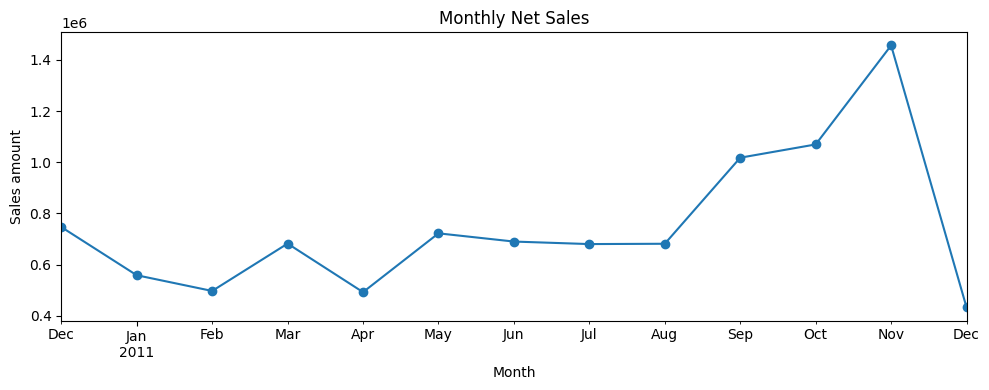

In [17]:
import matplotlib.pyplot as plt

monthly_sales = (
    df.set_index("invoicedate")
      .resample("MS")["sales"]
      .sum()
)

plt.figure(figsize=(10, 4))
monthly_sales.plot(
    marker="o",
    title="Monthly Net Sales"
)
plt.xlabel("Month")
plt.ylabel("Sales amount")
plt.tight_layout()
plt.show()

5.2 Category and product performance

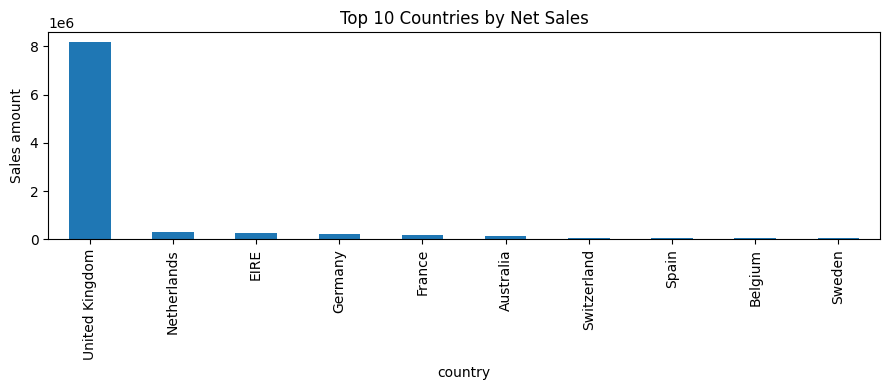

In [19]:
country_sales = (df.groupby("country")["sales"]
                     .sum().sort_values(ascending=False))

# Plot top 10 countries to avoid an overcrowded chart
country_sales.head(10).plot(kind="bar", figsize=(9, 4),
                            title="Top 10 Countries by Net Sales")
plt.ylabel("Sales amount")
plt.tight_layout()
plt.show()

7. Recommended End-to-End Python Workflow


Shape: (541909, 8)
Data Types:
 invoiceno              object
stockcode              object
description            object
quantity                int64
invoicedate    datetime64[ns]
unitprice             float64
customerid            float64
country                object
dtype: object
Missing values:
 invoiceno           0
stockcode           0
description      1454
quantity            0
invoicedate         0
unitprice           0
customerid     135080
country             0
dtype: int64
                count   unique                                 top    freq  \
invoiceno    541909.0  25900.0                            573585.0  1114.0   
stockcode      541909     4070                              85123A    2313   
description    540455     4223  WHITE HANGING HEART T-LIGHT HOLDER    2369   
quantity     541909.0      NaN                                 NaN     NaN   
invoicedate    541909      NaN                                 NaN     NaN   
unitprice    541909.0      NaN          

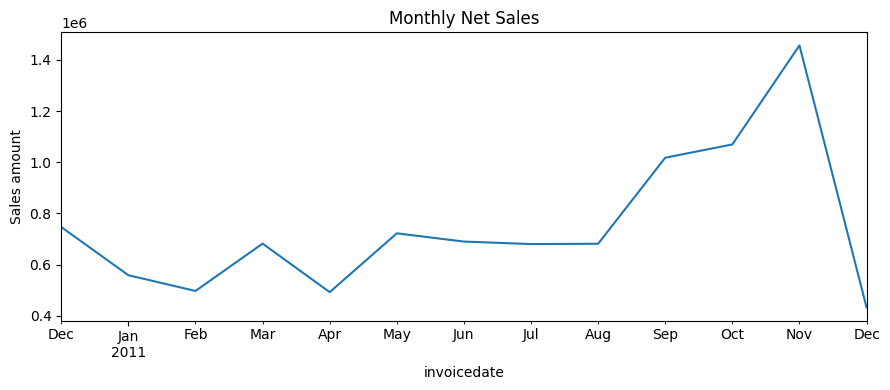

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import RobustScaler

# 1. Load and preserve the source
raw = pd.read_excel("Online Retail.xlsx")
df = raw.copy()

# 2. Standardise schema and parse dates
df.columns = (df.columns.str.strip().str.lower()
                        .str.replace(" ", "_"))
df["invoicedate"] = pd.to_datetime(
    df["invoicedate"], errors="coerce"
)

# 3. Profile data before changing it
print("Shape:", df.shape)
print("Data Types:\n", df.dtypes)
print("Missing values:\n", df.isna().sum())
print(df.describe(include="all").T)

# 4. Remove exact duplicates; retain an audit count
exact_duplicates = df.duplicated().sum()
df = df.drop_duplicates()
print(f"Removed {exact_duplicates} exact duplicate rows.")

# 5. Standardise description column (surrogate for category in this dataset)
df["description"] = (df["description"].astype("string")
                                  .str.strip().str.title())

# 6. Create quality flags instead of silently deleting records
df["invalid_price"] = (
    df["unitprice"].notna() & (df["unitprice"] < 0)
)
df["missing_customer_id"] = df["customerid"].isna()

# 7. Calculate sales
df["sales"] = df["quantity"] * df["unitprice"]

# 8. Derive date features
df["year"] = df["invoicedate"].dt.year
df["month"] = df["invoicedate"].dt.month
df["day_of_week"] = df["invoicedate"].dt.day_name()

# 9. Create analysis outputs
monthly = (df.dropna(subset=["invoicedate"])
             .set_index("invoicedate")
             .resample("MS")["sales"].sum())

plt.figure(figsize=(9, 4))
monthly.plot(title="Monthly Net Sales")
plt.ylabel("Sales amount")
plt.tight_layout()
plt.show()

# 10. Export cleaned data and quality exceptions
df.to_csv("retail_cleaned_for_analysis.csv", index=False)
df[df["invalid_price"]].to_csv(
    "retail_data_quality_exceptions.csv", index=False
)